# 02. Modelado Predictivo y Automatización — Rendimiento en Matemáticas
**Asignatura:** SCY1102 — Duoc UC | **Caso 1:** Rendimiento Académico Estudiantil (Kaggle)


## Importar librerías y definir parámetros

- `pandas` y `numpy`: manejo de datos.
- `matplotlib` y `seaborn`: gráficos.
- `scikit-learn`: preparación de datos, modelos y métricas.
- `joblib`: guardar el modelo para la automatización (paso 8).

**Parámetros:** el dataset de entrenamiento es muy grande (más de 8 millones de filas en el EDA). Para que el notebook sea rápido, entrenamos con una muestra aleatoria y más adelante comprobamos si usar más datos habría mejorado el modelo. Puedes cambiar estos valores.

In [1]:
import warnings, time, json, subprocess, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ---------- Parámetros que puedes cambiar ----------
SEMILLA = 42               # para que los resultados se puedan repetir
N_ENTRENAMIENTO = 500_000  # filas de train usadas para entrenar
N_EVALUACION = 500_000     # máximo de filas de validation/test usadas para evaluar
N_GRAFICOS = 10_000        # filas usadas en gráficos de puntos (para que no sean lentos)

# Nombres en español solo para mostrar (no cambian las columnas reales)
nombres_es = {
    "Age": "Edad", "Grade": "Grado escolar", "Gender": "Género",
    "Race": "Grupo étnico (según fuente)", "SES_Quartile": "Cuartil socioeconómico",
    "ParentalEducation": "Educación de los padres", "SchoolType": "Tipo de escuela",
    "Locale": "Zona de residencia", "TestScore_Math": "Puntaje de matemáticas",
    "TestScore_Reading": "Puntaje de lectura", "TestScore_Science": "Puntaje de ciencias",
    "GPA": "Promedio académico (GPA)", "AttendanceRate": "Tasa de asistencia",
    "StudyHours": "Tiempo de estudio (unidad por confirmar)", "InternetAccess": "Acceso a internet",
    "Extracurricular": "Participación extracurricular", "PartTimeJob": "Trabajo a tiempo parcial",
    "ParentSupport": "Apoyo parental", "Romantic": "Relación sentimental (según fuente)",
    "FreeTime": "Tiempo libre", "GoOut": "Salidas sociales"
}
objetivo = "TestScore_Math"
print("Librerías y parámetros listos.")

Librerías y parámetros listos.


## Paso 1. Cargar el dataset del proyecto

Tenemos tres archivos con las mismas columnas. Cada uno cumple un rol distinto:

- **train**: los datos con los que el modelo *aprende*.
- **validation**: datos que el modelo no ve al aprender; sirven para comparar modelos y detectar problemas.
- **test**: datos guardados para la evaluación final. No se usan para tomar decisiones, así la nota final es honesta.

La función busca los archivos en las carpetas más comunes (`../data/raw`, `data/raw`, `.`). Si los tienes en otro lugar, escribe la ruta en `RUTA_MANUAL`.

In [2]:
RUTA_MANUAL = None   # ejemplo: "C:/proyecto/datos"  (déjalo en None para buscar solo)

def buscar_archivo(nombres):
    carpetas = [RUTA_MANUAL] if RUTA_MANUAL else []
    carpetas += ["../data/raw", "data/raw", "../data", "data", "."]
    for carpeta in carpetas:
        for nombre in nombres:
            ruta = Path(carpeta) / nombre
            if ruta.exists():
                return ruta
    raise FileNotFoundError(f"No encontré {nombres}. Indica la carpeta en RUTA_MANUAL.")

ruta_train = buscar_archivo(["train.csv"])
ruta_val = buscar_archivo(["validation.csv", "val.csv", "valid.csv"])
ruta_test = buscar_archivo(["test.csv"])

# Tipos de dato: texto como categoría y números como float32 (ahorra memoria con millones de filas)
columnas_texto = ["Gender", "Race", "ParentalEducation", "SchoolType", "Locale"]
tipos = {c: "category" for c in columnas_texto}
tipos.update({c: "float32" for c in nombres_es if c not in columnas_texto})

inicio = time.time()
df_train = pd.read_csv(ruta_train, dtype=tipos)
df_val = pd.read_csv(ruta_val, dtype=tipos)
df_test = pd.read_csv(ruta_test, dtype=tipos)
print(f"Archivos leídos en {time.time() - inicio:.0f} segundos.\n")

conjuntos = {"Train": df_train, "Validation": df_val, "Test": df_test}
resumen_carga = pd.DataFrame({
    "Archivo": [ruta_train.name, ruta_val.name, ruta_test.name],
    "Registros": [len(d) for d in conjuntos.values()],
    "Variables": [d.shape[1] for d in conjuntos.values()],
    "Incluye puntaje de matemáticas": [objetivo in d.columns for d in conjuntos.values()],
}, index=list(conjuntos))
display(resumen_carga)

mismas = all(set(df_train.columns) - {objetivo} == set(d.columns) - {objetivo} for d in conjuntos.values())
print("¿Los tres archivos tienen las mismas columnas (sin contar el puntaje)?", "Sí" if mismas else "NO, revisar")
TEST_TIENE_OBJETIVO = objetivo in df_test.columns

display(df_train.head().rename(columns=nombres_es))

Archivos leídos en 4 segundos.



,Archivo,Registros,Variables,Incluye puntaje de matemáticas
Train,train.csv,8000774,21,True
Validation,validation.csv,999229,21,True
Test,test.csv,999997,21,True


¿Los tres archivos tienen las mismas columnas (sin contar el puntaje)? Sí


,Edad,Grado escolar,Género,Grupo étnico (según fuente),Cuartil socioeconómico,Educación de los padres,Tipo de escuela,Zona de residencia,Puntaje de matemáticas,Puntaje de lectura,...,Promedio académico (GPA),Tasa de asistencia,Tiempo de estudio (unidad por confirmar),Acceso a internet,Participación extracurricular,Trabajo a tiempo parcial,Apoyo parental,Relación sentimental (según fuente),Tiempo libre,Salidas sociales
0,17.0,12.0,Female,White,3.0,HS,Public,Suburban,70.258232,79.665184,...,2.743879,0.906809,1.089243,1.0,1.0,0.0,0.0,0.0,2.0,2.0
1,18.0,12.0,Female,White,2.0,HS,Public,Suburban,67.876549,59.611504,...,2.587700,0.843739,0.879911,1.0,1.0,0.0,1.0,0.0,5.0,2.0
2,16.0,11.0,Female,White,2.0,HS,Public,City,62.070621,70.577446,...,2.426294,0.850923,1.003442,1.0,1.0,0.0,1.0,1.0,5.0,1.0
3,14.0,9.0,Female,White,4.0,Bachelors+,Public,Town,79.909309,82.924454,...,3.558240,0.946786,1.814810,1.0,1.0,0.0,1.0,0.0,4.0,2.0
4,16.0,11.0,Female,Two-or-more,4.0,SomeCollege,Public,Rural,90.562294,95.352333,...,3.896884,0.988036,1.157241,1.0,1.0,0.0,0.0,0.0,3.0,4.0


**Cómo interpretar:** la tabla muestra cuántos estudiantes hay en cada archivo y confirma que los tres tienen las mismas columnas. Si `test.csv` no trajera el puntaje de matemáticas, no podríamos medir el error en él (el notebook lo detecta y usa validation para la evaluación final).

## Paso 2. Analizar las clases y generar gráficos representativos

Como el puntaje es continuo, las **clases** que analizamos son las **categorías de las variables** (educación de los padres, acceso a internet, etc.). Primero miramos la variable que queremos predecir y después cómo se reparten las clases y si estas se relacionan con el puntaje.

### 2.1 ¿Cómo se distribuye el puntaje de matemáticas?

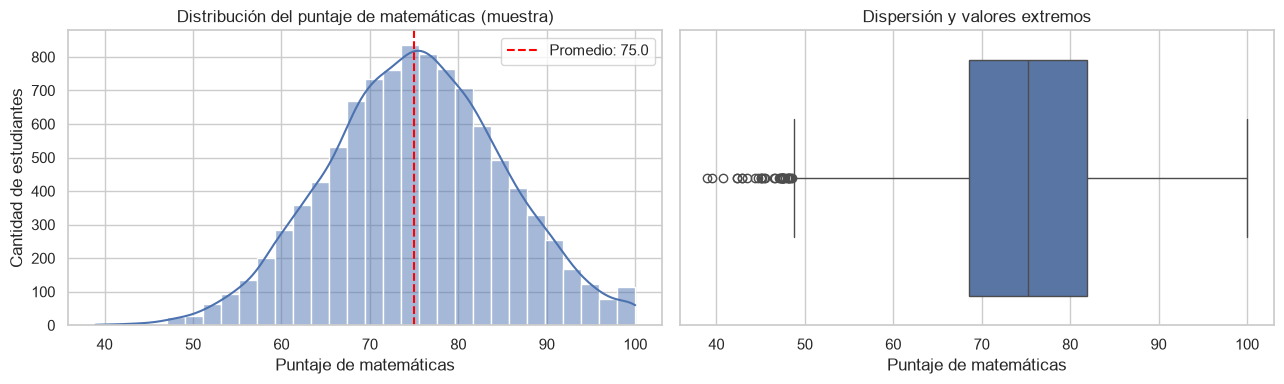

Promedio: 74.98 | Mediana: 75.00 | Desviación estándar: 9.94
Mínimo: 22.58 | Máximo: 100.00
Estudiantes con el puntaje máximo (100): 0.62% del total


In [3]:
muestra_graf = df_train.sample(n=min(N_GRAFICOS, len(df_train)), random_state=SEMILLA)
y = df_train[objetivo]

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(muestra_graf[objetivo], bins=30, kde=True, ax=ejes[0])
ejes[0].axvline(y.mean(), color="red", linestyle="--", label=f"Promedio: {y.mean():.1f}")
ejes[0].set_title("Distribución del puntaje de matemáticas (muestra)")
ejes[0].set_xlabel("Puntaje de matemáticas"); ejes[0].set_ylabel("Cantidad de estudiantes")
ejes[0].legend()
sns.boxplot(x=muestra_graf[objetivo], ax=ejes[1])
ejes[1].set_title("Dispersión y valores extremos"); ejes[1].set_xlabel("Puntaje de matemáticas")
plt.tight_layout(); plt.show()

print(f"Promedio: {y.mean():.2f} | Mediana: {y.median():.2f} | Desviación estándar: {y.std():.2f}")
print(f"Mínimo: {y.min():.2f} | Máximo: {y.max():.2f}")
print(f"Estudiantes con el puntaje máximo (100): {(y >= 100).mean() * 100:.2f}% del total")

**Cómo interpretar:** el histograma muestra dónde se concentran los puntajes; la línea roja es el promedio. Si promedio y mediana son parecidos, la distribución es bastante simétrica. Fíjate también en cuántos estudiantes llegan a **100**: ese es un *techo* de la escala, y por eso más adelante limitamos las predicciones entre 0 y 100.

### 2.2 ¿Train, validation y test se parecen?
Si los tres conjuntos vinieran de poblaciones distintas, el modelo funcionaría bien en train y mal en test. Lo revisamos comparando el puntaje.

In [4]:
filas = {}
for nombre, d in conjuntos.items():
    if objetivo in d.columns:
        s = d[objetivo]
        filas[nombre] = {"Registros": len(s), "Promedio": s.mean(), "Mediana": s.median(),
                         "Desv. estándar": s.std(), "Mínimo": s.min(), "Máximo": s.max()}
display(pd.DataFrame(filas).T.round(2))

,Registros,Promedio,Mediana,Desv. estándar,Mínimo,Máximo
Train,8000774.0,74.98,75.0,9.94,22.58,100.0
Validation,999229.0,74.97,75.0,9.95,24.96,100.0
Test,999997.0,74.98,75.0,9.94,29.15,100.0


**Cómo interpretar:** si los promedios y desviaciones son casi iguales, los conjuntos son comparables y tiene sentido entrenar con uno y evaluar con otro.

### 2.3 Las clases: ¿cuántos estudiantes hay en cada categoría?
Un grupo muy pequeño da promedios poco confiables, por eso miramos el tamaño de cada clase.

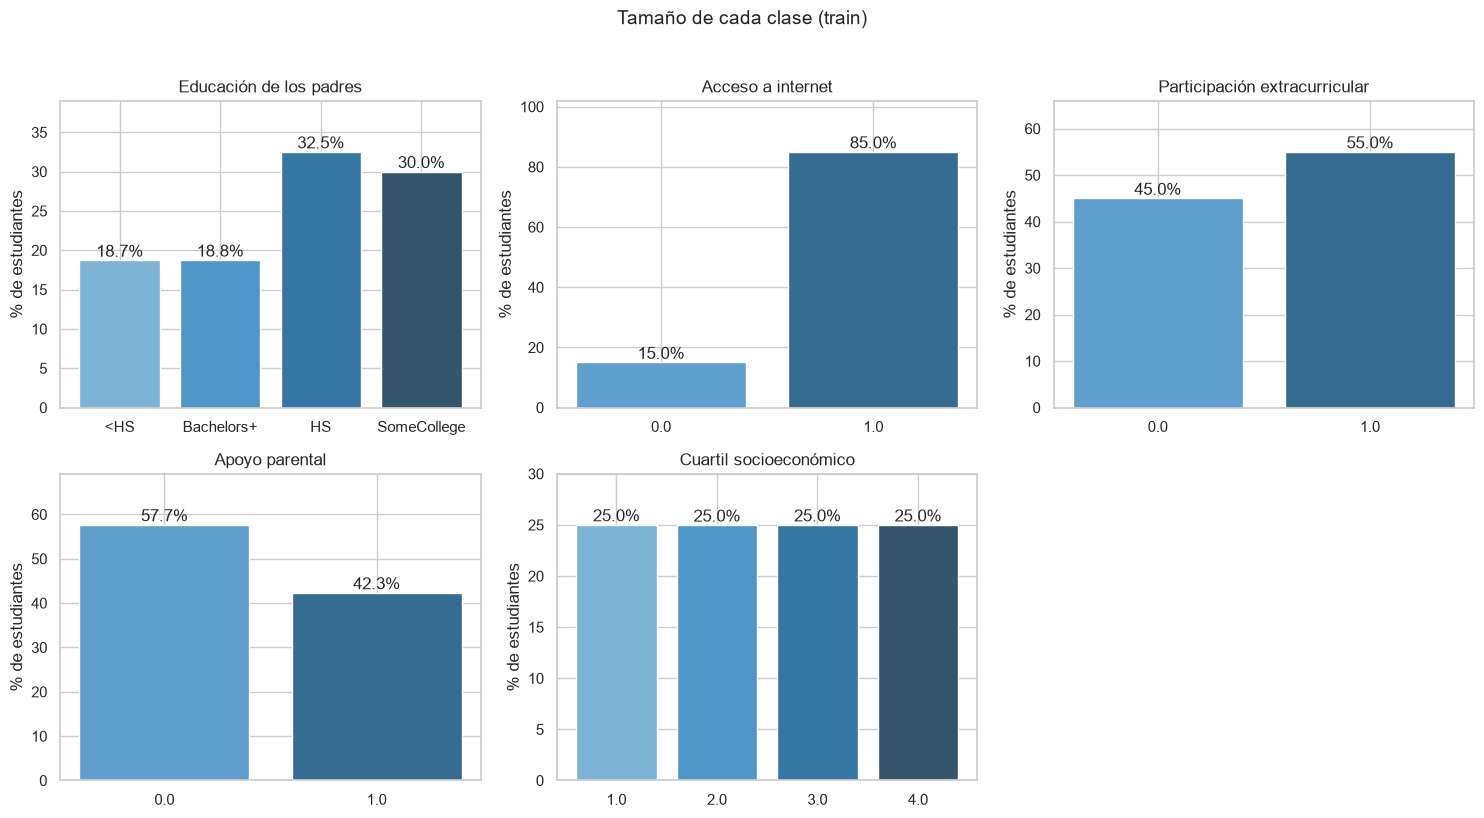

In [5]:
variables_clase = ["ParentalEducation", "InternetAccess", "Extracurricular", "ParentSupport", "SES_Quartile"]

fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
ejes = ejes.ravel()
for eje, col in zip(ejes, variables_clase):
    porcentaje = df_train[col].value_counts(normalize=True).sort_index() * 100
    barras = eje.bar(porcentaje.index.astype(str), porcentaje.values, color=sns.color_palette("Blues_d", len(porcentaje)))
    eje.bar_label(barras, fmt="%.1f%%")
    eje.set_title(nombres_es[col]); eje.set_ylabel("% de estudiantes")
    eje.set_ylim(0, porcentaje.max() * 1.2)
ejes[-1].axis("off")
plt.suptitle("Tamaño de cada clase (train)", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

**Cómo interpretar:** cada gráfico muestra qué porcentaje de estudiantes pertenece a cada clase. Los códigos `0` y `1` se mantienen como vienen en el archivo (confirmar su significado con el diccionario de datos). Si una clase tuviera muy pocos estudiantes, sus resultados habría que tomarlos con cuidado.

### 2.4 ¿El puntaje promedio cambia según la clase?
Dibujamos el promedio de cada clase con su intervalo de confianza del 95 %. **Importante:** todos los gráficos usan la misma escala vertical (promedio ± 1 desviación estándar) para no exagerar diferencias pequeñas.

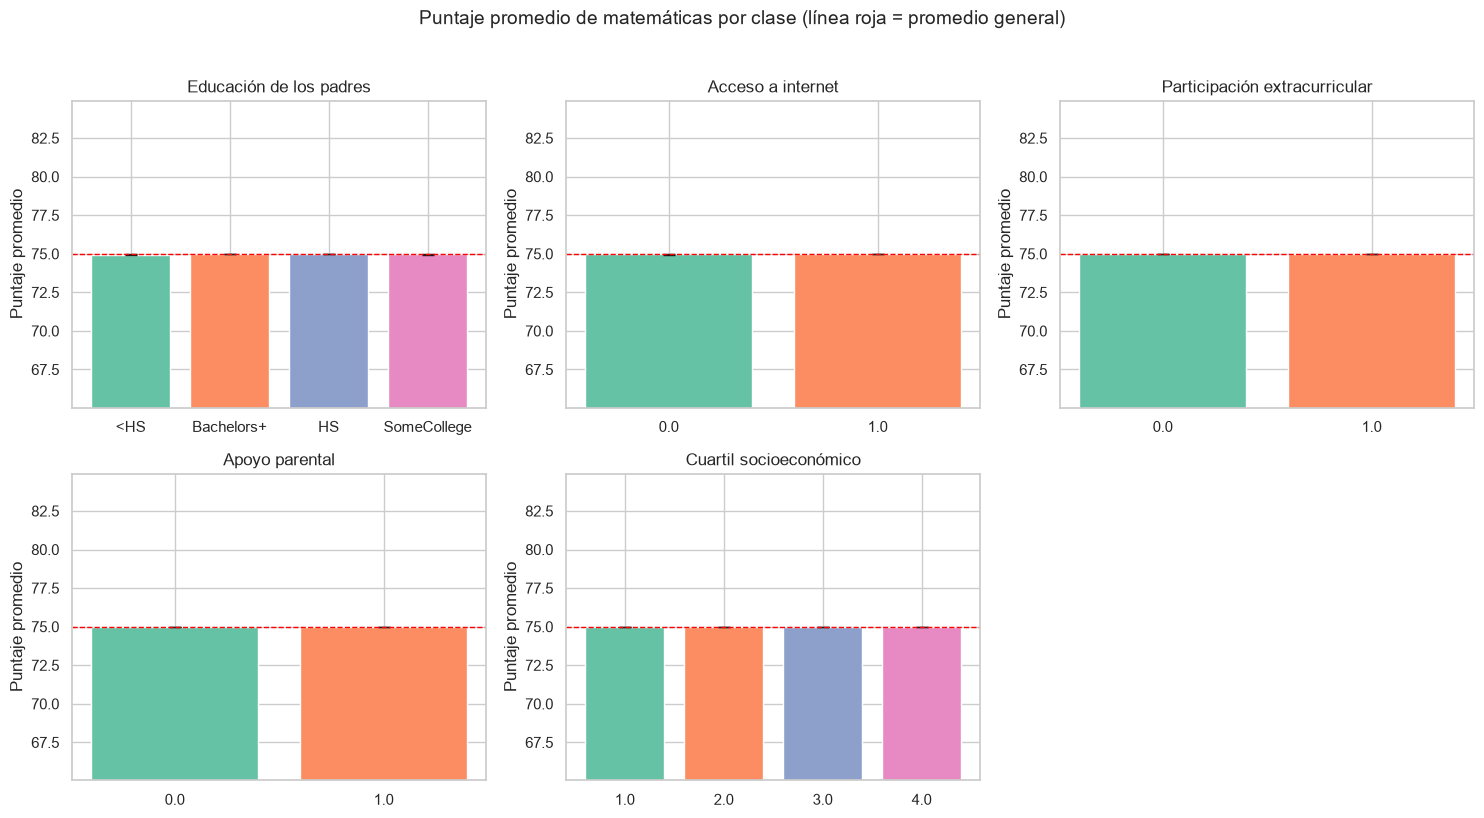

,Diferencia entre promedios extremos (puntos),Diferencia como % de la desviación estándar
Variable,,
Educación de los padres,0.04,0.44
Acceso a internet,0.01,0.09
Participación extracurricular,0.00,0.04
Apoyo parental,0.01,0.09
Cuartil socioeconómico,0.02,0.20


In [6]:
media_global, desv_global = y.mean(), y.std()
resumen_dif = []

fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
ejes = ejes.ravel()
for eje, col in zip(ejes, variables_clase):
    g = df_train.groupby(col, observed=True)[objetivo].agg(["count", "mean", "std"])
    g["ic95"] = 1.96 * g["std"] / np.sqrt(g["count"])
    eje.bar(g.index.astype(str), g["mean"], yerr=g["ic95"], capsize=4, color=sns.color_palette("Set2", len(g)))
    eje.axhline(media_global, color="red", linestyle="--", linewidth=1)
    eje.set_ylim(media_global - desv_global, media_global + desv_global)
    eje.set_title(nombres_es[col]); eje.set_ylabel("Puntaje promedio")
    dif = g["mean"].max() - g["mean"].min()
    resumen_dif.append({"Variable": nombres_es[col], "Diferencia entre promedios extremos (puntos)": dif,
                        "Diferencia como % de la desviación estándar": dif / desv_global * 100})
ejes[-1].axis("off")
plt.suptitle("Puntaje promedio de matemáticas por clase (línea roja = promedio general)", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

display(pd.DataFrame(resumen_dif).round(2).set_index("Variable"))

**Cómo interpretar:** si las barras llegan casi a la misma altura que la línea roja, esa variable **casi no separa** a los estudiantes por puntaje. La tabla resume la diferencia entre la mejor y la peor clase; si es una fracción mínima de la desviación estándar, el efecto práctico es muy pequeño (aunque con millones de filas cualquier diferencia pueda parecer "estadísticamente significativa").

### 2.5 Variables numéricas: ¿cuáles se mueven junto con el puntaje?

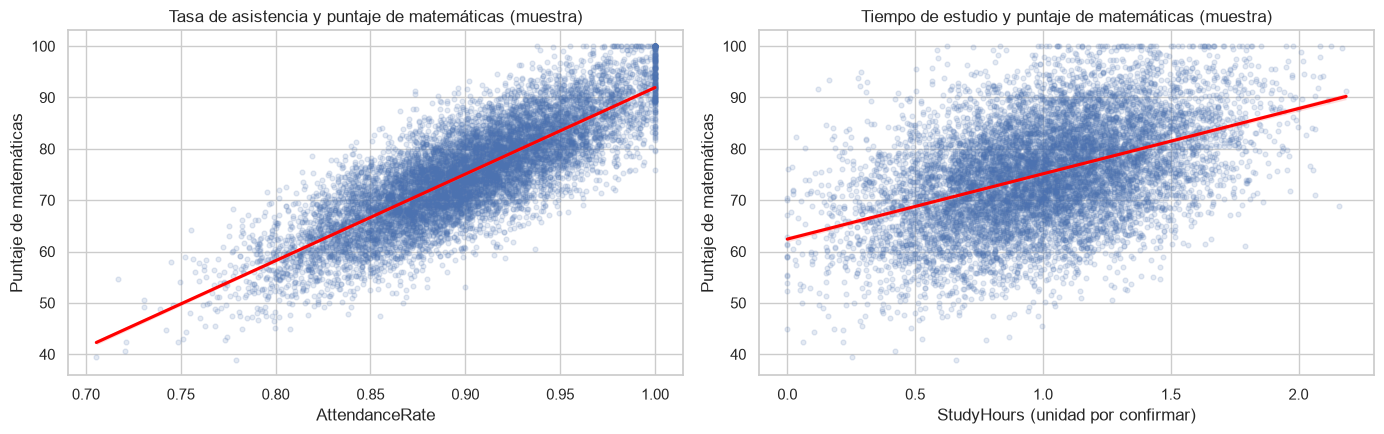

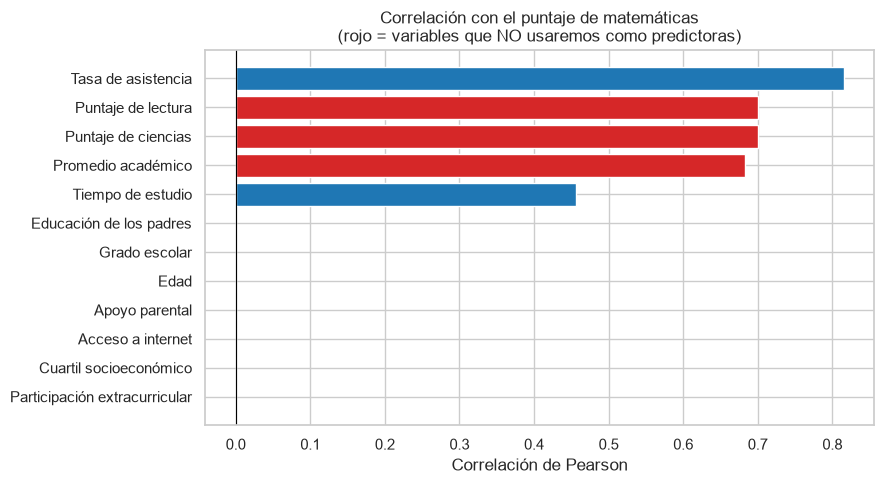

,Correlación
Tasa de asistencia,0.815
Puntaje de lectura,0.700
Puntaje de ciencias,0.700
Promedio académico (GPA),0.683
Tiempo de estudio (unidad por confirmar),0.456
Educación de los padres,0.001
Grado escolar,0.001
Edad,0.001
Apoyo parental,0.000
Acceso a internet,0.000


In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
for eje, col in zip(ejes, ["AttendanceRate", "StudyHours"]):
    sns.regplot(data=muestra_graf, x=col, y=objetivo, ax=eje,
                scatter_kws={"alpha": 0.15, "s": 12}, line_kws={"color": "red"})
    eje.set_title(f"{nombres_es[col].split(' (')[0]} y puntaje de matemáticas (muestra)")
    eje.set_xlabel(col + (" (unidad por confirmar)" if col == "StudyHours" else ""))
    eje.set_ylabel("Puntaje de matemáticas")
plt.tight_layout(); plt.show()

# Correlación de cada candidata con el puntaje (educación parental se ordena solo para este cálculo)
orden_educ = {"<HS": 0, "HS": 1, "SomeCollege": 2, "Bachelors+": 3}
candidatas = ["Age", "Grade", "SES_Quartile", "StudyHours", "AttendanceRate", "InternetAccess",
              "ParentSupport", "Extracurricular", "TestScore_Reading", "TestScore_Science", "GPA"]
tabla_corr = df_train[candidatas].copy()
tabla_corr["ParentalEducation"] = df_train["ParentalEducation"].astype(str).map(orden_educ).astype("float32")
corr_obj = tabla_corr.corrwith(df_train[objetivo]).sort_values()

colores = ["#d62728" if c in ("TestScore_Reading", "TestScore_Science", "GPA") else "#1f77b4" for c in corr_obj.index]
plt.figure(figsize=(9, 5))
plt.barh([nombres_es.get(c, c).split(" (")[0] for c in corr_obj.index], corr_obj.values, color=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlación con el puntaje de matemáticas\n(rojo = variables que NO usaremos como predictoras)")
plt.xlabel("Correlación de Pearson")
plt.tight_layout(); plt.show()
display(corr_obj.sort_values(ascending=False).rename(index=lambda c: nombres_es.get(c, c)).to_frame("Correlación").round(3))

**Cómo interpretar:** cada punto es un estudiante y la línea roja es la tendencia. Una línea inclinada hacia arriba indica que, a mayor valor, mayor puntaje. En las barras, valores cercanos a 1 son asociaciones fuertes y cercanos a 0 son débiles.

Las barras **rojas** (lectura, ciencias y GPA) correlacionan mucho con matemáticas, pero **no las usamos para predecir**: son resultados del mismo período, así que "ya contienen" parte de la respuesta. Usarlas sería hacer trampa (en ciencia de datos se llama *fuga de información*). Y recuerda: **correlación no es causalidad**.

## Paso 3. Preparar los datos y elegir variables

### 3.1 Revisar la calidad de los datos en los tres conjuntos
Buscamos faltantes, filas repetidas, valores fuera de rango y valores extremos. No borramos nada automáticamente: primero entendemos qué pasa.

In [8]:
def muestra_hasta(d, n=1_000_000):
    return d.sample(n=n, random_state=SEMILLA) if len(d) > n else d

# Rangos que esperamos (confirmar con el diccionario de datos)
rangos = {"TestScore_Math": (0, 100), "AttendanceRate": (0, 1), "InternetAccess": (0, 1),
          "Extracurricular": (0, 1), "ParentSupport": (0, 1), "SES_Quartile": (1, 4), "StudyHours": (0, np.inf)}

calidad = []
for nombre, d in conjuntos.items():
    fuera = 0
    for col, (minimo, maximo) in rangos.items():
        if col in d.columns:
            fuera += int(((d[col] < minimo) | (d[col] > maximo)).sum())
    calidad.append({"Conjunto": nombre,
                    "Celdas faltantes": int(d.isnull().sum().sum()),
                    "Filas repetidas (en muestra de hasta 1 millón)": int(muestra_hasta(d).duplicated().sum()),
                    "Valores fuera de rango": fuera})
display(pd.DataFrame(calidad).set_index("Conjunto"))

q1, q3 = y.quantile([0.25, 0.75])
limite_inf, limite_sup = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
n_extremos = int(((y < limite_inf) | (y > limite_sup)).sum())
print(f"Valores extremos del puntaje (regla del rango intercuartílico): {n_extremos} ({n_extremos / len(y) * 100:.2f}%)")
print(f"Rango 'normal' del puntaje: de {limite_inf:.1f} a {limite_sup:.1f}")

,Celdas faltantes,Filas repetidas (en muestra de hasta 1 millón),Valores fuera de rango
Conjunto,,,
Train,0,0,0
Validation,0,0,0
Test,0,0,0


Valores extremos del puntaje (regla del rango intercuartílico): 27806 (0.35%)
Rango 'normal' del puntaje: de 48.0 a 102.0


**Cómo interpretar:** lo ideal es ver ceros en las tres primeras columnas. Si hubiera faltantes, el modelo los rellena (más abajo) usando solo información de train. Los valores extremos **no se eliminan**: un puntaje muy alto o bajo puede ser real y es justo el tipo de estudiante que nos interesa entender.

### 3.2 Variable dependiente e independientes
- **Variable dependiente (lo que queremos predecir):** `TestScore_Math`.
- **Variables independientes (lo que usamos para predecir):** las mismas candidatas que dejamos listadas en el EDA.

In [9]:
variables_numericas = ["Age", "Grade", "SES_Quartile", "StudyHours", "AttendanceRate",
                       "InternetAccess", "ParentSupport", "Extracurricular"]
variables_categoricas = ["ParentalEducation"]
variables_independientes = variables_numericas + variables_categoricas

decisiones = pd.DataFrame([
    ["TestScore_Math", "Variable dependiente", "Es lo que queremos predecir."],
    *[[c, "Independiente (usada)", "Candidata definida en el EDA y disponible antes de la evaluación."] for c in variables_independientes],
    ["TestScore_Reading / TestScore_Science / GPA", "Excluida", "Mismo período que el resultado: fuga de información."],
    ["Gender / Race", "Excluida", "Variables sensibles: no queremos que el apoyo académico dependa de ellas."],
    ["SchoolType, Locale, PartTimeJob, Romantic, FreeTime, GoOut", "No incluida por ahora", "No estaban en la lista del EDA; se pueden probar en una mejora futura."],
], columns=["Variable", "Rol", "Motivo"])
display(decisiones)

,Variable,Rol,Motivo
0,TestScore_Math,Variable dependiente,Es lo que queremos predecir.
1,Age,Independiente (usada),Candidata definida en el EDA y disponible ante...
2,Grade,Independiente (usada),Candidata definida en el EDA y disponible ante...
3,SES_Quartile,Independiente (usada),Candidata definida en el EDA y disponible ante...
4,StudyHours,Independiente (usada),Candidata definida en el EDA y disponible ante...
5,AttendanceRate,Independiente (usada),Candidata definida en el EDA y disponible ante...
6,InternetAccess,Independiente (usada),Candidata definida en el EDA y disponible ante...
7,ParentSupport,Independiente (usada),Candidata definida en el EDA y disponible ante...
8,Extracurricular,Independiente (usada),Candidata definida en el EDA y disponible ante...
9,ParentalEducation,Independiente (usada),Candidata definida en el EDA y disponible ante...


### 3.3 Transformaciones que necesita el modelo
Los modelos trabajan con números, así que definimos tres transformaciones:

1. **Rellenar faltantes** (si los hubiera): mediana en números y valor más frecuente en categorías.
2. **Escalar** los números (solo para la regresión lineal): deja todas las variables en una escala parecida.
3. **Codificar categorías** (*one-hot*): convierte `ParentalEducation` en columnas de 0 y 1.

**Regla de oro:** estas transformaciones se *aprenden solo con train* y luego se aplican a validation y test. Si las aprendiéramos con todos los datos, estaríamos filtrando información del futuro. Por eso las ponemos dentro de un `Pipeline` que hace todo en el orden correcto.

In [10]:
def crear_preprocesador(escalar):
    pasos_num = [("imputar", SimpleImputer(strategy="median"))]
    if escalar:
        pasos_num.append(("escalar", StandardScaler()))
    return ColumnTransformer([
        ("numericas", Pipeline(pasos_num), variables_numericas),
        ("categoricas", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                                  ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
         variables_categoricas),
    ])

def preparar_X(d):
    X = d[variables_independientes].copy()
    X["ParentalEducation"] = X["ParentalEducation"].astype(object)   # permite rellenar faltantes
    return X

print("Preprocesador definido. Variables numéricas:", len(variables_numericas), "| categóricas:", len(variables_categoricas))

Preprocesador definido. Variables numéricas: 8 | categóricas: 1


## Paso 4. Separar los datos en entrenamiento, validación y test

Los archivos ya vienen separados, así que **respetamos esa separación**:

- Entrenamos con una muestra aleatoria de `train`.
- Comparamos modelos y buscamos problemas con `validation`.
- Dejamos `test` para la nota final (paso 6).

Antes de seguir comprobamos que la muestra de train represente bien al train completo.

In [11]:
def separar(d, maximo):
    d = d.dropna(subset=[objetivo])
    if len(d) > maximo:
        d = d.sample(n=maximo, random_state=SEMILLA)
    return preparar_X(d), d[objetivo].astype("float64")

X_train, y_train = separar(df_train, N_ENTRENAMIENTO)
X_val, y_val = separar(df_val, N_EVALUACION)
if TEST_TIENE_OBJETIVO:
    X_test, y_test = separar(df_test, N_EVALUACION)
else:
    X_test, y_test = preparar_X(df_test.head(N_EVALUACION)), None

tamanos = pd.DataFrame({
    "Conjunto": ["Entrenamiento (muestra de train)", "Validación", "Test"],
    "Registros usados": [len(X_train), len(X_val), len(X_test)],
    "Promedio del puntaje": [y_train.mean(), y_val.mean(), y_test.mean() if y_test is not None else np.nan],
}).set_index("Conjunto")
display(tamanos.round(2))

print(f"Promedio del puntaje en TODO train: {y.mean():.2f}  |  en la muestra de entrenamiento: {y_train.mean():.2f}")
dist_muestra = X_train["ParentalEducation"].value_counts(normalize=True).sort_index() * 100
dist_total = df_train["ParentalEducation"].astype(str).value_counts(normalize=True).sort_index() * 100
display(pd.DataFrame({"% en train completo": dist_total, "% en la muestra": dist_muestra}).round(2).rename_axis("Educación de los padres"))

,Registros usados,Promedio del puntaje
Conjunto,,
Entrenamiento (muestra de train),500000,74.99
Validación,500000,74.96
Test,500000,74.98


Promedio del puntaje en TODO train: 74.98  |  en la muestra de entrenamiento: 74.99


,% en train completo,% en la muestra
Educación de los padres,,
<HS,18.73,18.71
Bachelors+,18.75,18.77
HS,32.51,32.49
SomeCollege,30.01,30.02


**Cómo interpretar:** los promedios y los porcentajes de la muestra deben ser casi idénticos a los del train completo. Si lo son, entrenar con la muestra es una buena aproximación y mucho más rápido. En el paso 5 comprobamos además si usar más datos mejoraría el resultado.

## Paso 5. Entrenar el modelo y analizar si los pasos anteriores fueron suficientes

Entrenamos tres modelos, de menos a más complejo:

1. **Línea base (promedio):** predice siempre el promedio de train. Es el "modelo tonto". Cualquier modelo útil debe superarlo.
2. **Regresión lineal:** suma el aporte de cada variable. Simple y fácil de explicar.
3. **Gradient Boosting:** combina muchos árboles pequeños y puede capturar relaciones que no son líneas rectas.

### 5.1 Entrenamiento

In [12]:
def crear_modelos():
    return {
        "Línea base (promedio)": Pipeline([("prep", crear_preprocesador(True)), ("modelo", DummyRegressor(strategy="mean"))]),
        "Regresión lineal": Pipeline([("prep", crear_preprocesador(True)), ("modelo", LinearRegression())]),
        "Gradient Boosting": Pipeline([("prep", crear_preprocesador(False)),
                                       ("modelo", HistGradientBoostingRegressor(max_iter=200, learning_rate=0.1, random_state=SEMILLA))]),
    }

modelos = crear_modelos()
for nombre, modelo in modelos.items():
    t0 = time.time()
    modelo.fit(X_train, y_train)
    print(f"{nombre:<24} entrenado en {time.time() - t0:5.1f} segundos")

Línea base (promedio)    entrenado en   0.5 segundos
Regresión lineal         entrenado en   0.6 segundos
Gradient Boosting        entrenado en   1.5 segundos


### 5.2 Métricas que usaremos
Todas están en **puntos de la prueba**, así se entienden directamente:

- **MAE:** error promedio. "En promedio, el modelo se equivoca en X puntos."
- **RMSE:** parecido al MAE pero castiga más los errores grandes.
- **R²:** qué parte de la variación de los puntajes explica el modelo (0 = nada, 1 = todo).
- **% dentro de ±5 / ±10 puntos:** porcentaje de estudiantes cuya predicción quedó cerca del puntaje real.

Las predicciones se limitan entre 0 y 100 porque ese es el rango real de la prueba.

In [13]:
def calcular_metricas(y_real, y_pred):
    y_pred = np.clip(y_pred, 0, 100)
    error = y_pred - np.asarray(y_real)
    return {"MAE (puntos)": mean_absolute_error(y_real, y_pred),
            "RMSE (puntos)": np.sqrt(mean_squared_error(y_real, y_pred)),
            "R²": r2_score(y_real, y_pred),
            "% dentro de ±5 pts": np.mean(np.abs(error) <= 5) * 100,
            "% dentro de ±10 pts": np.mean(np.abs(error) <= 10) * 100}

filas = []
for nombre, modelo in modelos.items():
    m_train = calcular_metricas(y_train, modelo.predict(X_train))
    m_val = calcular_metricas(y_val, modelo.predict(X_val))
    filas.append({"Modelo": nombre, "Conjunto": "Entrenamiento", **m_train})
    filas.append({"Modelo": nombre, "Conjunto": "Validación", **m_val})
tabla_5 = pd.DataFrame(filas).set_index(["Modelo", "Conjunto"])
display(tabla_5.round(3))

solo_val = tabla_5.xs("Validación", level="Conjunto")
mejor_nombre = solo_val["RMSE (puntos)"].idxmin()
print(f"\nMejor modelo según el error en validación (RMSE más bajo): {mejor_nombre}")

MAE (puntos)  RMSE (puntos)     R²  \
Modelo                Conjunto                                            
Línea base (promedio) Entrenamiento         7.966          9.952  0.000   
                      Validación            7.972          9.953 -0.000   
Regresión lineal      Entrenamiento         4.555          5.694  0.673   
                      Validación            4.562          5.703  0.672   
Gradient Boosting     Entrenamiento         4.543          5.681  0.674   
                      Validación            4.559          5.702  0.672   

                                     % dentro de ±5 pts  % dentro de ±10 pts  
Modelo                Conjunto                                                
Línea base (promedio) Entrenamiento              38.359               68.160  
                      Validación                 38.235               68.130  
Regresión lineal      Entrenamiento              61.684               92.233  
                      Validación                 61.644               92.132  
Gradient Boosting     Entrenamiento              61.857               92.230  
                      Validación                 61.698               92.065


Mejor modelo según el error en validación (RMSE más bajo): Gradient Boosting


**Cómo interpretar:** compara cada fila con la **línea base**. Si el modelo reduce el error (MAE y RMSE) y el R² sube respecto a la línea base, está aprendiendo algo real. Si el error en *entrenamiento* es mucho menor que en *validación*, el modelo memoriza en vez de aprender (sobreajuste).

### 5.3 Revisión visual de los errores del mejor modelo
Si los pasos anteriores fueron suficientes, los errores deberían ser pequeños, estar centrados en 0 y no depender de ninguna variable en particular.

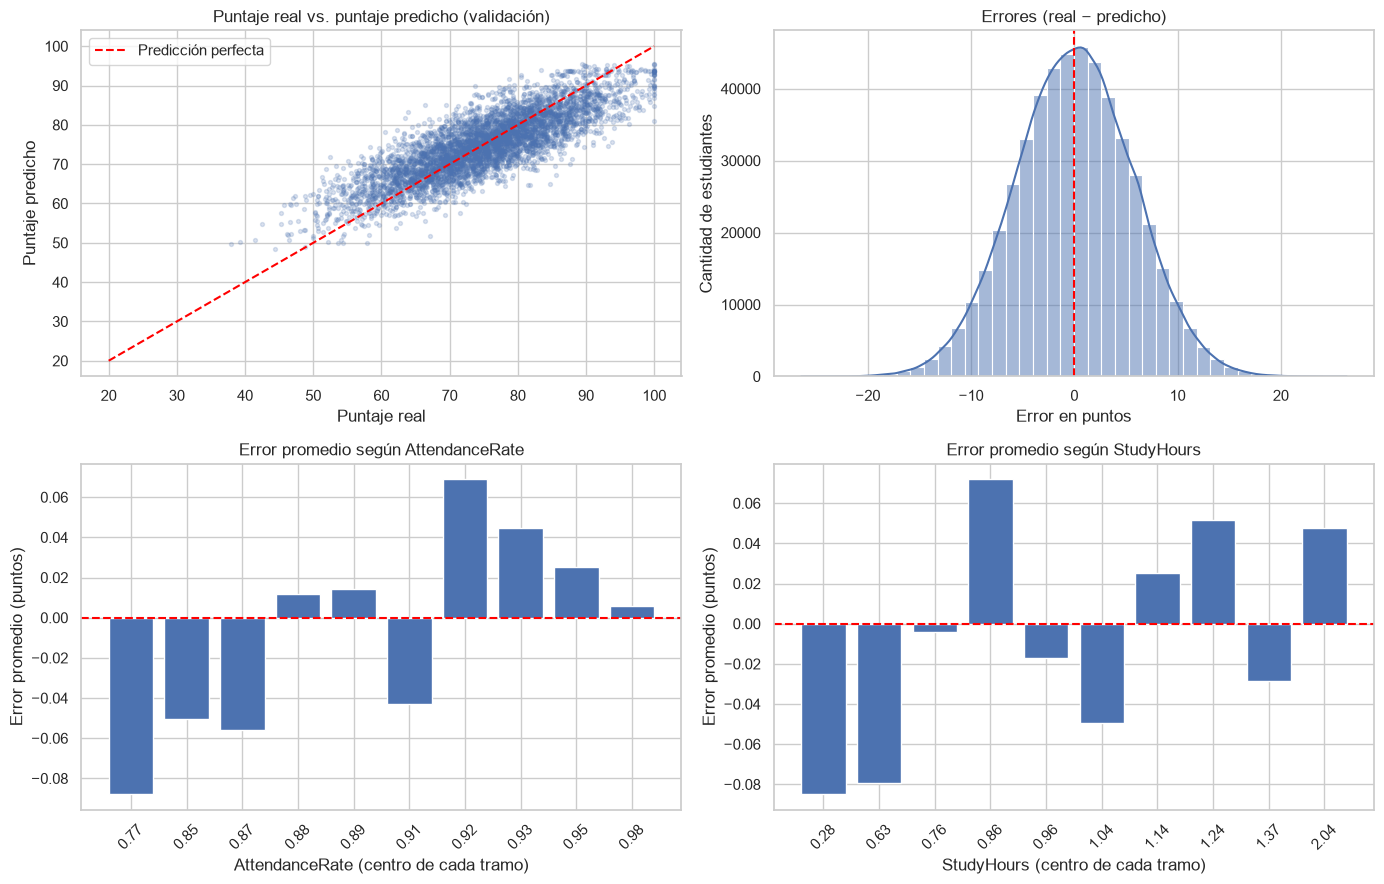

In [14]:
modelo_final = modelos[mejor_nombre]
pred_val = np.clip(modelo_final.predict(X_val), 0, 100)
residuo = y_val.values - pred_val     # real - predicho

muestra_idx = np.random.default_rng(SEMILLA).choice(len(y_val), size=min(5000, len(y_val)), replace=False)
fig, ejes = plt.subplots(2, 2, figsize=(14, 9))

ejes[0, 0].scatter(y_val.values[muestra_idx], pred_val[muestra_idx], alpha=0.2, s=8)
ejes[0, 0].plot([20, 100], [20, 100], color="red", linestyle="--", label="Predicción perfecta")
ejes[0, 0].set_title("Puntaje real vs. puntaje predicho (validación)")
ejes[0, 0].set_xlabel("Puntaje real"); ejes[0, 0].set_ylabel("Puntaje predicho"); ejes[0, 0].legend()

sns.histplot(residuo, bins=40, kde=True, ax=ejes[0, 1])
ejes[0, 1].axvline(0, color="red", linestyle="--")
ejes[0, 1].set_title("Errores (real − predicho)"); ejes[0, 1].set_xlabel("Error en puntos"); ejes[0, 1].set_ylabel("Cantidad de estudiantes")

for eje, col in zip([ejes[1, 0], ejes[1, 1]], ["AttendanceRate", "StudyHours"]):
    tramos = pd.qcut(X_val[col], 10, duplicates="drop")
    por_tramo = pd.Series(residuo).groupby(tramos.values, observed=True).mean()
    eje.bar(range(len(por_tramo)), por_tramo.values, color="#4c72b0")
    eje.axhline(0, color="red", linestyle="--")
    eje.set_xticks(range(len(por_tramo)))
    eje.set_xticklabels([f"{i.mid:.2f}" for i in por_tramo.index], rotation=45)
    eje.set_title(f"Error promedio según {col}")
    eje.set_xlabel(col + " (centro de cada tramo)"); eje.set_ylabel("Error promedio (puntos)")
plt.tight_layout(); plt.show()

**Cómo interpretar:**
- **Arriba izquierda:** cuanto más pegados a la línea roja estén los puntos, mejor la predicción. Una nube muy ancha indica mucho error.
- **Arriba derecha:** los errores deberían formar una campana centrada en 0.
- **Abajo:** si las barras se alejan de 0 en algunos tramos, el modelo se equivoca de forma sistemática en ese tipo de estudiantes (por ejemplo, los de asistencia muy baja o muy alta).

### 5.4 ¿Más datos de entrenamiento ayudarían? (curva de aprendizaje)
Entrenamos el mejor modelo con cantidades crecientes de filas. Si el error deja de bajar, más datos no ayudan y el límite está en las variables disponibles, no en la cantidad de datos.

,RMSE entrenamiento,RMSE validación
Filas de entrenamiento,,
5000,4.331,6.001
20000,5.541,5.731
100000,5.655,5.710
500000,5.681,5.702


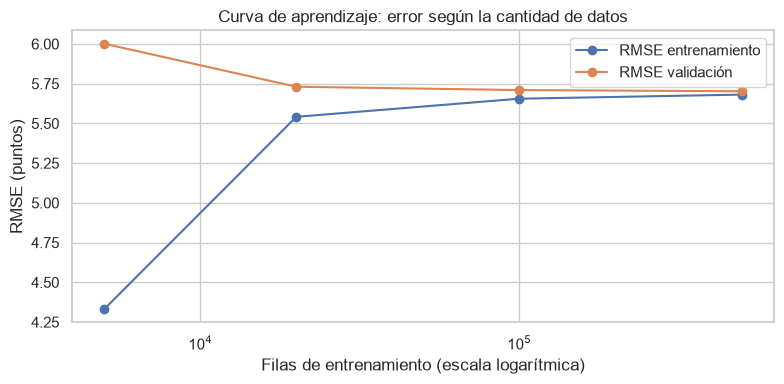

In [15]:
tamanos_prueba = [n for n in [5_000, 20_000, 100_000, 500_000, len(X_train)] if n <= len(X_train)]
tamanos_prueba = sorted(set(tamanos_prueba))
curva = []
for n in tamanos_prueba:
    m = clone(modelos[mejor_nombre]).fit(X_train.iloc[:n], y_train.iloc[:n])
    curva.append({"Filas de entrenamiento": n,
                  "RMSE entrenamiento": calcular_metricas(y_train.iloc[:n], m.predict(X_train.iloc[:n]))["RMSE (puntos)"],
                  "RMSE validación": calcular_metricas(y_val, m.predict(X_val))["RMSE (puntos)"]})
curva = pd.DataFrame(curva).set_index("Filas de entrenamiento")
display(curva.round(3))

curva.plot(marker="o", figsize=(8, 4), logx=True)
plt.title("Curva de aprendizaje: error según la cantidad de datos")
plt.xlabel("Filas de entrenamiento (escala logarítmica)"); plt.ylabel("RMSE (puntos)")
plt.tight_layout(); plt.show()

**Cómo interpretar:** si la línea de validación se aplana, el modelo ya "aprendió todo lo que podía" con estas variables. Si las dos líneas están muy separadas, hay sobreajuste.

### 5.5 ¿Qué variables usa más el modelo? (importancia por permutación)
Se desordena una variable a la vez y se mide cuánto empeora el modelo. Cuanto más empeora, más depende de esa variable.

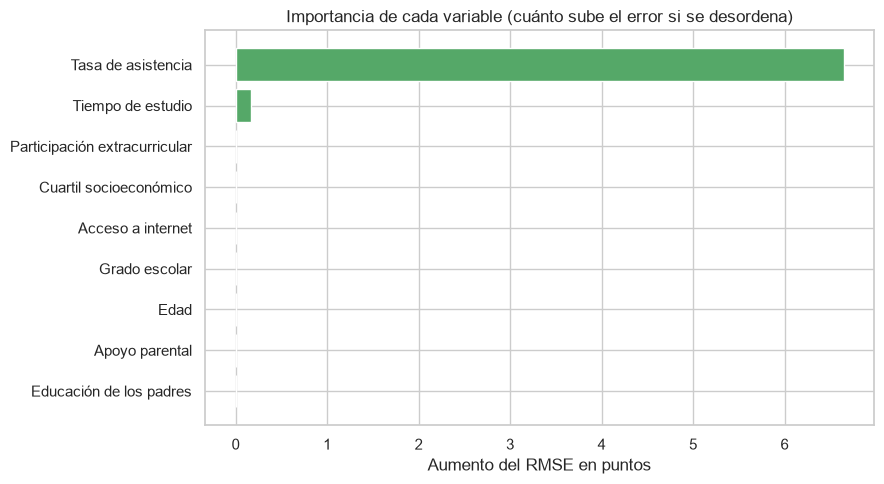

,Aumento del error (puntos)
Tasa de asistencia,6.645
Tiempo de estudio (unidad por confirmar),0.166
Participación extracurricular,0.000
Cuartil socioeconómico,0.000
Acceso a internet,0.000
Grado escolar,0.000
Edad,-0.000
Apoyo parental,-0.000
Educación de los padres,-0.000


In [16]:
n_imp = min(20_000, len(X_val))
idx = np.random.default_rng(SEMILLA).choice(len(X_val), size=n_imp, replace=False)
imp = permutation_importance(modelo_final, X_val.iloc[idx], y_val.iloc[idx], n_repeats=3,
                             scoring="neg_root_mean_squared_error", random_state=SEMILLA)
importancia = pd.Series(imp.importances_mean, index=X_val.columns).sort_values()

plt.figure(figsize=(9, 5))
plt.barh([nombres_es[c].split(" (")[0] for c in importancia.index], importancia.values, color="#55a868")
plt.title("Importancia de cada variable (cuánto sube el error si se desordena)")
plt.xlabel("Aumento del RMSE en puntos"); plt.tight_layout(); plt.show()
display(importancia.sort_values(ascending=False).rename(index=lambda c: nombres_es[c]).to_frame("Aumento del error (puntos)").round(3))

**Cómo interpretar:** las barras largas son las variables que realmente sostienen las predicciones. Las barras casi nulas aportan muy poco; coincide con lo que vimos en el EDA, donde varias categorías apenas cambiaban el promedio.

### 5.6 Veredicto: ¿fueron suficientes los pasos anteriores?
Aplicamos una lista de control con criterios simples y explícitos (son criterios de este proyecto, no reglas universales).

In [17]:
rmse_base = solo_val.loc["Línea base (promedio)", "RMSE (puntos)"]
rmse_mejor = solo_val.loc[mejor_nombre, "RMSE (puntos)"]
rmse_entrena = tabla_5.loc[(mejor_nombre, "Entrenamiento"), "RMSE (puntos)"]
r2_val = solo_val.loc[mejor_nombre, "R²"]

mejora = (1 - rmse_mejor / rmse_base) * 100
brecha = (rmse_mejor - rmse_entrena) / rmse_entrena * 100
sesgo = residuo.mean()
if len(curva) >= 2:
    ganancia_datos = (curva["RMSE validación"].iloc[-2] - curva["RMSE validación"].iloc[-1]) / curva["RMSE validación"].iloc[-2] * 100
else:
    ganancia_datos = np.nan
faltantes_total = int(X_train.isnull().sum().sum())

criterios = [
    (f"Datos sin problemas pendientes (faltantes en el entrenamiento: {faltantes_total})", faltantes_total == 0),
    (f"El modelo mejora a la línea base en {mejora:.1f}% de error (mínimo pedido: 10%)", mejora >= 10),
    (f"No hay sobreajuste: error de validación {brecha:.1f}% mayor que el de entrenamiento (máximo: 5%)", brecha <= 5),
    (f"Errores centrados en cero: sesgo promedio de {sesgo:.2f} puntos (máximo: ±0.5)", abs(sesgo) <= 0.5),
    (f"Más datos ya no ayudan: el último aumento de datos mejoró el error solo {max(ganancia_datos, 0):.1f}% (menos de 2%)", ganancia_datos < 2),
]
for texto, cumple in criterios:
    print(("[OK]       " if cumple else "[REVISAR]  ") + texto)

nivel = "alto" if r2_val >= 0.6 else "moderado" if r2_val >= 0.3 else "bajo"
print(f"\nR² en validación = {r2_val:.3f}: el modelo explica un {r2_val * 100:.0f}% de la variación de los puntajes (poder explicativo {nivel}).")
if all(c for _, c in criterios):
    print("Veredicto: los pasos anteriores fueron suficientes para desarrollar el modelo.")
else:
    print("Veredicto: el modelo funciona, pero hay puntos marcados [REVISAR] que conviene mejorar antes de usarlo en serio.")

[OK]       Datos sin problemas pendientes (faltantes en el entrenamiento: 0)
[OK]       El modelo mejora a la línea base en 42.7% de error (mínimo pedido: 10%)
[OK]       No hay sobreajuste: error de validación 0.4% mayor que el de entrenamiento (máximo: 5%)
[OK]       Errores centrados en cero: sesgo promedio de -0.01 puntos (máximo: ±0.5)
[OK]       Más datos ya no ayudan: el último aumento de datos mejoró el error solo 0.1% (menos de 2%)

R² en validación = 0.672: el modelo explica un 67% de la variación de los puntajes (poder explicativo alto).
Veredicto: los pasos anteriores fueron suficientes para desarrollar el modelo.


**Cómo interpretar:** cada línea `[OK]` es un chequeo superado y cada `[REVISAR]` es un punto de mejora. Si todo sale bien pero el R² no llega a 1, no es un error: significa que **hay factores que determinan el puntaje y no están en el dataset** (por ejemplo, el método de estudio, la motivación o la calidad de las clases).

## Paso 6. Evaluar los resultados con métricas de desempeño

Ahora usamos el conjunto **test**, que no se usó para ninguna decisión. Es la medida más honesta de cómo funcionaría el modelo con estudiantes nuevos.

Resultados en Test (500,000 estudiantes):


,MAE (puntos),RMSE (puntos),R²,% dentro de ±5 pts,% dentro de ±10 pts
Modelo,,,,,
Línea base (promedio),7.968,9.952,-0.000,38.213,68.218
Regresión lineal,4.553,5.695,0.672,61.736,92.222
Gradient Boosting,4.550,5.694,0.673,61.776,92.156


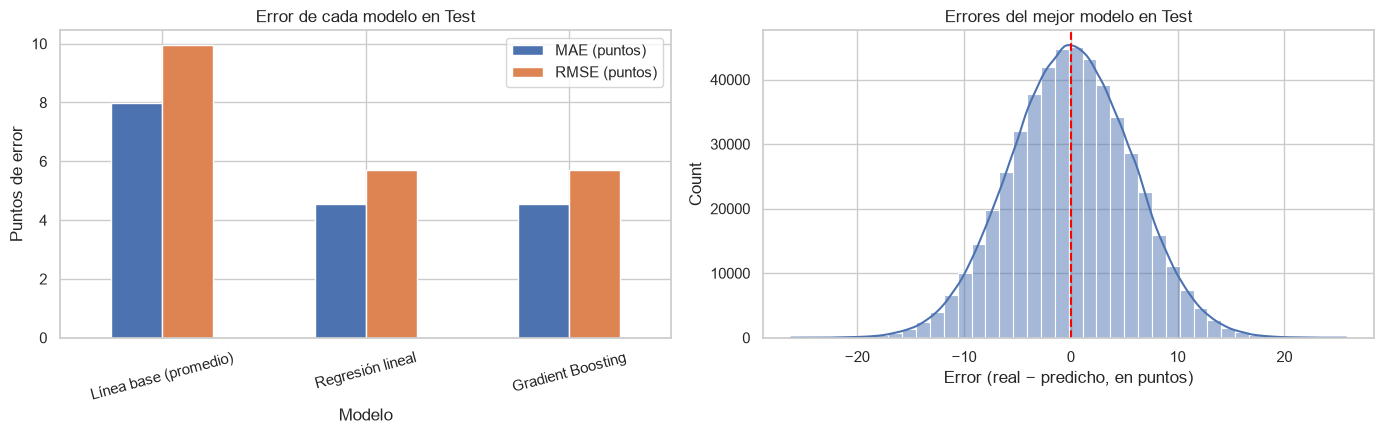

In [18]:
if TEST_TIENE_OBJETIVO:
    nombre_eval, X_eval, y_eval = "Test", X_test, y_test
else:
    print("test.csv no trae el puntaje de matemáticas: la evaluación final se hace con validation.")
    nombre_eval, X_eval, y_eval = "Validación", X_val, y_val

filas = []
for nombre, modelo in modelos.items():
    filas.append({"Modelo": nombre, **calcular_metricas(y_eval, modelo.predict(X_eval))})
tabla_6 = pd.DataFrame(filas).set_index("Modelo")
print(f"Resultados en {nombre_eval} ({len(y_eval):,} estudiantes):")
display(tabla_6.round(3))

pred_eval = np.clip(modelo_final.predict(X_eval), 0, 100)
error_eval = y_eval.values - pred_eval
met = tabla_6.loc[mejor_nombre]
rmse_test = met["RMSE (puntos)"]; r2_test = met["R²"]; mae_test = met["MAE (puntos)"]

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
tabla_6[["MAE (puntos)", "RMSE (puntos)"]].plot(kind="bar", ax=ejes[0], rot=15)
ejes[0].set_title(f"Error de cada modelo en {nombre_eval}"); ejes[0].set_ylabel("Puntos de error")
sns.histplot(error_eval, bins=40, kde=True, ax=ejes[1])
ejes[1].axvline(0, color="red", linestyle="--")
ejes[1].set_title(f"Errores del mejor modelo en {nombre_eval}"); ejes[1].set_xlabel("Error (real − predicho, en puntos)")
plt.tight_layout(); plt.show()

**Cómo interpretar:** el mejor modelo debería tener las barras más bajas. Si el error en test es parecido al de validación, el modelo es **estable** y se comportará de forma similar con datos nuevos.

### ¿En qué tipo de estudiantes se equivoca más?
Un buen modelo no solo tiene un error promedio bajo: también debe equivocarse parecido en todos los grupos.

In [19]:
analisis = X_eval.copy()
analisis["error_absoluto"] = np.abs(error_eval)
analisis["error"] = error_eval
analisis["Tramo de asistencia"] = pd.qcut(analisis["AttendanceRate"], 5, duplicates="drop").astype(str)

por_asistencia = analisis.groupby("Tramo de asistencia", observed=True).agg(
    Estudiantes=("error", "size"), MAE=("error_absoluto", "mean"), Sesgo=("error", "mean")).round(2)
por_educacion = analisis.groupby("ParentalEducation", observed=True).agg(
    Estudiantes=("error", "size"), MAE=("error_absoluto", "mean"), Sesgo=("error", "mean")).round(2)
display(por_asistencia.rename_axis("Tramo de asistencia (5 grupos iguales)"))
display(por_educacion.rename_axis("Educación de los padres"))

,Estudiantes,MAE,Sesgo
Tramo de asistencia (5 grupos iguales),,,
"(0.699, 0.859]",100000,4.57,-0.06
"(0.859, 0.888]",100000,4.56,-0.00
"(0.888, 0.912]",100001,4.56,0.02
"(0.912, 0.941]",99999,4.56,0.04
"(0.941, 1.0]",100000,4.50,0.05


,Estudiantes,MAE,Sesgo
Educación de los padres,,,
<HS,93594,4.56,0.04
Bachelors+,93631,4.53,0.03
HS,162243,4.55,-0.03
SomeCollege,150532,4.56,0.02


**Cómo interpretar:** `MAE` es el error promedio del grupo y `Sesgo` indica si el modelo tiende a sobrestimar (negativo) o subestimar (positivo). Si un grupo tiene un error claramente mayor, el modelo es menos confiable para esos estudiantes.

## Paso 7. Usar el modelo con datos nuevos: 5 predicciones

Creamos 5 estudiantes ficticios con perfiles distintos. Para que los valores sean realistas sin conocer la unidad de `StudyHours`, usamos **percentiles del propio train** (p10 = muy bajo, p50 = típico, p90 = muy alto).

Datos de entrada de los 5 estudiantes nuevos:


,Edad,Grado escolar,Cuartil socioeconómico,Tiempo de estudio (unidad por confirmar),Tasa de asistencia,Acceso a internet,Apoyo parental,Participación extracurricular,Educación de los padres
Estudiante,,,,,,,,,
Perfil 1: alto compromiso,17,12,3,1.45,0.96,1,1,1,Bachelors+
Perfil 2: típico,16,11,2,1.00,0.90,1,0,1,HS
Perfil 3: bajo compromiso,16,11,2,0.55,0.84,0,0,0,HS
"Perfil 4: asiste mucho, estudia poco",15,10,3,0.55,0.96,1,1,0,SomeCollege
"Perfil 5: estudia mucho, asiste poco",17,12,1,1.45,0.84,0,0,1,<HS


,Puntaje predicho,Rango probable (±1 RMSE),Lectura
Estudiante,,,
Perfil 1: alto compromiso,86.0,80.3 a 91.7,Por encima del promedio
Perfil 2: típico,74.7,69.0 a 80.4,Cerca del promedio
Perfil 3: bajo compromiso,64.0,58.3 a 69.6,Por debajo del promedio
"Perfil 4: asiste mucho, estudia poco",83.6,78.0 a 89.3,Por encima del promedio
"Perfil 5: estudia mucho, asiste poco",66.6,60.9 a 72.2,Por debajo del promedio


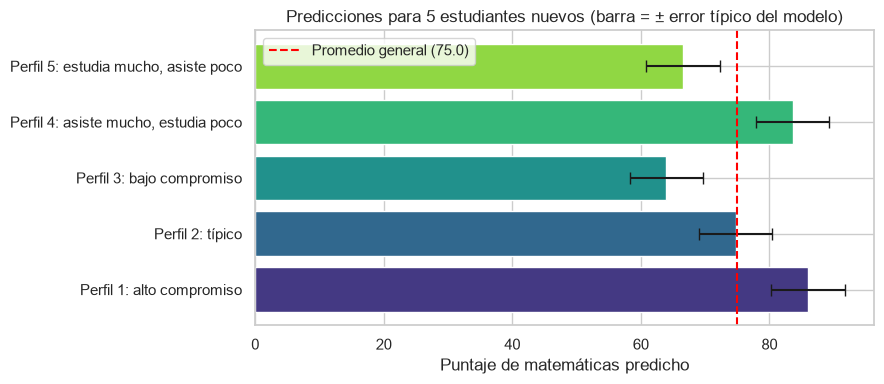

In [20]:
p = lambda col, q: float(df_train[col].quantile(q))

nuevos = pd.DataFrame([
    ["Perfil 1: alto compromiso",        17, 12, 3, "Bachelors+",  p("StudyHours", .9), p("AttendanceRate", .9), 1, 1, 1],
    ["Perfil 2: típico",                 16, 11, 2, "HS",          p("StudyHours", .5), p("AttendanceRate", .5), 1, 0, 1],
    ["Perfil 3: bajo compromiso",        16, 11, 2, "HS",          p("StudyHours", .1), p("AttendanceRate", .1), 0, 0, 0],
    ["Perfil 4: asiste mucho, estudia poco", 15, 10, 3, "SomeCollege", p("StudyHours", .1), p("AttendanceRate", .9), 1, 1, 0],
    ["Perfil 5: estudia mucho, asiste poco", 17, 12, 1, "<HS",       p("StudyHours", .9), p("AttendanceRate", .1), 0, 0, 1],
], columns=["Estudiante", "Age", "Grade", "SES_Quartile", "ParentalEducation", "StudyHours",
            "AttendanceRate", "InternetAccess", "ParentSupport", "Extracurricular"])
nuevos = nuevos.set_index("Estudiante")[variables_independientes]

print("Datos de entrada de los 5 estudiantes nuevos:")
display(nuevos.round(2).rename(columns=nombres_es))

X_nuevos = nuevos.copy()
X_nuevos["ParentalEducation"] = X_nuevos["ParentalEducation"].astype(object)
pred_nuevos = np.clip(modelo_final.predict(X_nuevos), 0, 100)

promedio_train = float(y.mean())
def lectura(puntaje):
    if puntaje >= promedio_train + 0.5 * desv_global: return "Por encima del promedio"
    if puntaje <= promedio_train - 0.5 * desv_global: return "Por debajo del promedio"
    return "Cerca del promedio"

resultado = pd.DataFrame({
    "Puntaje predicho": pred_nuevos,
    "Rango probable (±1 RMSE)": [f"{max(0, v - rmse_test):.1f} a {min(100, v + rmse_test):.1f}" for v in pred_nuevos],
    "Lectura": [lectura(v) for v in pred_nuevos],
}, index=nuevos.index).round(1)
display(resultado)

plt.figure(figsize=(9, 4))
plt.barh(nuevos.index, pred_nuevos, xerr=rmse_test, capsize=4, color=sns.color_palette("viridis", 5))
plt.axvline(promedio_train, color="red", linestyle="--", label=f"Promedio general ({promedio_train:.1f})")
plt.xlabel("Puntaje de matemáticas predicho"); plt.title("Predicciones para 5 estudiantes nuevos (barra = ± error típico del modelo)")
plt.legend(); plt.tight_layout(); plt.show()

**Cómo interpretar:** cada predicción es una **estimación**, no una certeza. El "rango probable" usa el error típico del modelo (RMSE): aproximadamente 2 de cada 3 estudiantes reales caen dentro de ese rango. Compara los perfiles 4 y 5: te muestran qué variable pesa más en el modelo, asistencia o estudio.

### Comprobación con estudiantes reales de test
Para confiar en el modelo, comparamos 5 predicciones con puntajes que sí conocemos.

In [21]:
if TEST_TIENE_OBJETIVO:
    idx5 = np.random.default_rng(7).choice(len(X_test), size=5, replace=False)
    comp = pd.DataFrame({"Puntaje real": y_test.iloc[idx5].values,
                         "Puntaje predicho": np.clip(modelo_final.predict(X_test.iloc[idx5]), 0, 100)})
    comp["Diferencia"] = comp["Puntaje predicho"] - comp["Puntaje real"]
    comp.index = [f"Estudiante test #{i}" for i in idx5]
    display(comp.round(1))
    print(f"Error absoluto promedio en estos 5 casos: {comp['Diferencia'].abs().mean():.1f} puntos (error promedio en todo test: {mae_test:.1f}).")
else:
    print("test.csv no trae el puntaje real, no se puede comparar.")

,Puntaje real,Puntaje predicho,Diferencia
Estudiante test #312545,66.1,71.4,5.3
Estudiante test #342088,79.4,80.7,1.2
Estudiante test #472448,72.2,75.2,3.1
Estudiante test #289146,86.1,89.4,3.2
Estudiante test #448606,84.3,73.5,-10.8


Error absoluto promedio en estos 5 casos: 4.7 puntos (error promedio en todo test: 4.5).


**Cómo interpretar:** con solo 5 casos el resultado varía mucho; no sirve para medir el modelo (eso ya lo hicimos con miles de estudiantes en el paso 6), pero ayuda a *ver* qué tan cerca queda una predicción individual.

## Paso 8. Proponer e implementar una automatización

### Propuesta
**Problema real:** cada vez que la institución tiene estudiantes nuevos, alguien tendría que abrir este notebook y ejecutarlo a mano. Eso es lento y propenso a errores.

**Solución propuesta:** un script que se ejecuta solo, con este flujo:

```
Carpeta con CSV nuevos  →  Validar columnas y rangos  →  Predecir con el modelo guardado
        →  Guardar CSV con predicciones y alerta "requiere apoyo"  →  Registrar y vigilar el error del modelo
```

**Qué incluye la implementación:**
1. El modelo entrenado se guarda en un archivo (`modelo_matematicas.joblib`).
2. Un script (`automatizacion_matematicas.py`) que lee un CSV, valida los datos, predice y guarda el resultado con fecha.
3. Una **alerta de apoyo**: marca a los estudiantes cuyo puntaje predicho está por debajo de un umbral editable (aquí, el percentil 25 de train, solo como ejemplo: la institución debe definir el suyo).
4. **Monitoreo:** si el CSV nuevo trae los puntajes reales, el script calcula el error y avisa si el modelo empeoró más de un 20 % respecto a validación (señal de que hay que reentrenar).
5. Instrucciones para programarlo (semanal, por ejemplo) sin abrir Jupyter.

In [22]:
CARPETA = Path("automatizacion_modelo")
(CARPETA / "entradas").mkdir(parents=True, exist_ok=True)
(CARPETA / "salidas").mkdir(exist_ok=True)

# 1) Guardar el modelo y sus metadatos
import sklearn
umbral_apoyo = float(y.quantile(0.25))
joblib.dump(modelo_final, CARPETA / "modelo_matematicas.joblib")
metadatos = {"modelo": mejor_nombre, "variables": variables_independientes,
             "rmse_validacion": float(rmse_mejor), "umbral_apoyo": umbral_apoyo,
             "version_sklearn": sklearn.__version__}
(CARPETA / "metadatos.json").write_text(json.dumps(metadatos, indent=2, ensure_ascii=False), encoding="utf-8")
print("Modelo guardado. Metadatos:")
print(json.dumps(metadatos, indent=2, ensure_ascii=False))

Modelo guardado. Metadatos:
{
  "modelo": "Gradient Boosting",
  "variables": [
    "Age",
    "Grade",
    "SES_Quartile",
    "StudyHours",
    "AttendanceRate",
    "InternetAccess",
    "ParentSupport",
    "Extracurricular",
    "ParentalEducation"
  ],
  "rmse_validacion": 5.702121448087603,
  "umbral_apoyo": 68.24698638916016,
  "version_sklearn": "1.9.1"
}


In [23]:
SCRIPT = r"""
# Automatización: predice el puntaje de matemáticas para un CSV de estudiantes.
# Uso:  python automatizacion_matematicas.py --entrada entradas/nuevos.csv

import argparse, json, sys
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import joblib

CARPETA = Path(__file__).parent

def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--entrada", required=True, help="CSV con los estudiantes")
    parser.add_argument("--salida", default=str(CARPETA / "salidas"), help="Carpeta de resultados")
    args = parser.parse_args()

    modelo = joblib.load(CARPETA / "modelo_matematicas.joblib")
    meta = json.loads((CARPETA / "metadatos.json").read_text(encoding="utf-8"))
    variables = meta["variables"]

    datos = pd.read_csv(args.entrada)
    faltan = [c for c in variables if c not in datos.columns]
    if faltan:
        print("ERROR: faltan columnas en el CSV:", faltan)
        sys.exit(1)

    X = datos[variables].copy()
    X["ParentalEducation"] = X["ParentalEducation"].astype(object)
    if X.isnull().any().any():
        print("AVISO: hay valores faltantes; el modelo los rellena con los valores aprendidos en entrenamiento.")

    pred = np.clip(modelo.predict(X), 0, 100)
    resultado = datos.copy()
    resultado["puntaje_predicho"] = pred.round(1)
    resultado["rango_min"] = np.clip(pred - meta["rmse_validacion"], 0, 100).round(1)
    resultado["rango_max"] = np.clip(pred + meta["rmse_validacion"], 0, 100).round(1)
    resultado["requiere_apoyo"] = pred < meta["umbral_apoyo"]

    Path(args.salida).mkdir(parents=True, exist_ok=True)
    nombre = "predicciones_" + datetime.now().strftime("%Y%m%d_%H%M%S") + ".csv"
    ruta = Path(args.salida) / nombre
    resultado.to_csv(ruta, index=False)
    print(f"{len(resultado)} estudiantes procesados. Resultado: {ruta}")
    print(f"Estudiantes marcados para apoyo (predicho < {meta['umbral_apoyo']:.1f}): {int(resultado['requiere_apoyo'].sum())}")

    # Monitoreo: solo si el archivo trae el puntaje real
    if "TestScore_Math" in datos.columns:
        real = datos["TestScore_Math"].astype(float)
        ok = real.notna()
        rmse = float(np.sqrt(np.mean((pred[ok.values] - real[ok]) ** 2)))
        print(f"Monitoreo: RMSE en estos datos = {rmse:.2f} (referencia en validación = {meta['rmse_validacion']:.2f})")
        if rmse > 1.2 * meta["rmse_validacion"]:
            print("ALERTA: el error subió más de 20%. Conviene reentrenar el modelo.")
        else:
            print("Monitoreo OK: el modelo mantiene su desempeño.")

    with open(CARPETA / "registro.log", "a", encoding="utf-8") as f:
        f.write(f"{datetime.now().isoformat()} | {args.entrada} | {len(resultado)} filas\n")

if __name__ == "__main__":
    main()
"""
(CARPETA / "automatizacion_matematicas.py").write_text(SCRIPT.lstrip(), encoding="utf-8")
print("Script creado en:", CARPETA / "automatizacion_matematicas.py")

Script creado en: automatizacion_modelo\automatizacion_matematicas.py


### Probar la automatización
Simulamos dos ejecuciones: (1) un CSV con los 5 estudiantes nuevos del paso 7 y (2) un CSV con 2.000 estudiantes de test que incluye el puntaje real, para activar el monitoreo.

In [24]:
# Entrada 1: estudiantes nuevos (sin puntaje real)
nuevos.reset_index(drop=True).to_csv(CARPETA / "entradas" / "nuevos_estudiantes.csv", index=False)
# Entrada 2: muestra de test con puntaje real (para monitoreo)
cols_entrada = variables_independientes + ([objetivo] if TEST_TIENE_OBJETIVO else [])
df_test.dropna(subset=variables_independientes).sample(n=min(2000, len(df_test)), random_state=SEMILLA)[cols_entrada] \
    .to_csv(CARPETA / "entradas" / "muestra_con_puntaje_real.csv", index=False)

archivos_resultado = {}
for archivo in ["nuevos_estudiantes.csv", "muestra_con_puntaje_real.csv"]:
    print("=" * 70, "\nEjecutando con:", archivo)
    r = subprocess.run([sys.executable, str(CARPETA / "automatizacion_matematicas.py"),
                        "--entrada", str(CARPETA / "entradas" / archivo)], capture_output=True, text=True)
    print(r.stdout, r.stderr)
    for linea in r.stdout.splitlines():
        if "Resultado:" in linea:
            archivos_resultado[archivo] = Path(linea.split("Resultado:")[1].strip())

ruta_nuevos = archivos_resultado["nuevos_estudiantes.csv"]
print("Vista del archivo de resultados de los estudiantes nuevos:", ruta_nuevos.name)
display(pd.read_csv(ruta_nuevos)[["StudyHours", "AttendanceRate", "puntaje_predicho", "rango_min", "rango_max", "requiere_apoyo"]].round(2))

Ejecutando con: nuevos_estudiantes.csv
5 estudiantes procesados. Resultado: c:\Users\sj-alumno\Downloads\Gestion\notebooks\automatizacion_modelo\salidas\predicciones_20261106_172357.csv
Estudiantes marcados para apoyo (predicho < 68.2): 2
 
Ejecutando con: muestra_con_puntaje_real.csv
2000 estudiantes procesados. Resultado: c:\Users\sj-alumno\Downloads\Gestion\notebooks\automatizacion_modelo\salidas\predicciones_20261106_172359.csv
Estudiantes marcados para apoyo (predicho < 68.2): 424
Monitoreo: RMSE en estos datos = 5.52 (referencia en validaciÃ³n = 5.70)
Monitoreo OK: el modelo mantiene su desempeÃ±o.
 
Vista del archivo de resultados de los estudiantes nuevos: predicciones_20261106_172357.csv


,StudyHours,AttendanceRate,puntaje_predicho,rango_min,rango_max,requiere_apoyo
0,1.45,0.96,86.0,80.3,91.7,False
1,1.00,0.90,74.7,69.0,80.4,False
2,0.55,0.84,64.0,58.2,69.7,True
3,0.55,0.96,83.6,77.9,89.3,False
4,1.45,0.84,66.6,60.9,72.3,True


**Cómo interpretar:** el script corrió "solo", sin usar el notebook. Generó un archivo con el puntaje predicho, el rango probable y si el estudiante requiere apoyo. En la segunda ejecución, el monitoreo comparó las predicciones con los puntajes reales y dijo si el modelo sigue funcionando bien.

### Cómo dejarlo programado (sin abrir Jupyter)
- **Linux / Mac (cron):** ejecuta `crontab -e` y agrega, por ejemplo, un lunes a las 7:00:  
  `0 7 * * 1 python /ruta/automatizacion_modelo/automatizacion_matematicas.py --entrada /ruta/entradas/nuevos.csv`
- **Windows:** *Programador de tareas* → crear tarea básica → acción "Iniciar un programa" → `python` con los argumentos del script.
- **En la nube:** una tarea programada de GitHub Actions o similar puede ejecutar el mismo comando.

**Mejoras futuras:** reentrenar automáticamente cuando salte la alerta del monitoreo, enviar el resultado por correo al equipo de tutorías y guardar un historial de métricas por fecha.

## Resumen automático de resultados
La siguiente celda toma los números reales de esta ejecución y los resume en lenguaje sencillo.

In [25]:
r2_lin = tabla_6.loc["Regresión lineal", "R²"]
r2_gb = tabla_6.loc["Gradient Boosting", "R²"]
relevantes = importancia[importancia > 0.05].sort_values(ascending=False)
if len(relevantes) > 0:
    top3_txt = ", ".join(nombres_es[c].split(" (")[0].lower() for c in relevantes.head(3).index)
    resto = len(importancia) - len(relevantes)
    top3_txt += f" (las otras {resto} variables casi no aportan)" if resto > 0 else ""
else:
    top3_txt = "ninguna destaca claramente"
cat_dif = pd.DataFrame(resumen_dif).set_index("Variable")["Diferencia entre promedios extremos (puntos)"]

display(Markdown(f"""
**Datos:** {len(df_train):,} estudiantes en train, {len(df_val):,} en validation y {len(df_test):,} en test.
Faltantes en el entrenamiento: {faltantes_total}. Promedio del puntaje: {promedio_train:.1f} (desviación {desv_global:.1f}).

**Modelo elegido:** {mejor_nombre}. En *{nombre_eval}* se equivoca en promedio **{mae_test:.1f} puntos** (RMSE {rmse_test:.1f}) y explica
un **{r2_test * 100:.0f}%** de la variación de los puntajes (R² = {r2_test:.3f}). La línea base tiene un error de {rmse_base:.1f} puntos (RMSE),
es decir, el modelo reduce el error en un **{mejora:.0f}%**.

**Variables más importantes para el modelo:** {top3_txt}.

**Clases (categorías):** la mayor diferencia entre promedios de una clase fue de **{cat_dif.max():.2f} puntos**
({cat_dif.idxmax().lower()}), frente a una desviación estándar de {desv_global:.1f} puntos.
"""))


**Datos:** 8,000,774 estudiantes en train, 999,229 en validation y 999,997 en test.
Faltantes en el entrenamiento: 0. Promedio del puntaje: 75.0 (desviación 9.9).

**Modelo elegido:** Gradient Boosting. En *Test* se equivoca en promedio **4.5 puntos** (RMSE 5.7) y explica
un **67%** de la variación de los puntajes (R² = 0.673). La línea base tiene un error de 10.0 puntos (RMSE),
es decir, el modelo reduce el error en un **43%**.

**Variables más importantes para el modelo:** tasa de asistencia, tiempo de estudio (las otras 7 variables casi no aportan).

**Clases (categorías):** la mayor diferencia entre promedios de una clase fue de **0.04 puntos**
(educación de los padres), frente a una desviación estándar de 9.9 puntos.


## Conclusiones

Lo que aprendí con este proyecto, dicho con mis palabras:

1. **Calidad de los datos.** Los tres archivos tienen la misma estructura y, según las revisiones del paso 3, no presentan problemas graves (faltantes, repetidos o valores fuera de rango). Aun así conviene confirmar con el diccionario de datos qué significan los códigos `0/1` y la unidad de `StudyHours`.

2. **Qué explica el puntaje de matemáticas.** En el análisis de clases vi que las categorías (educación de los padres, internet, actividades extracurriculares) casi **no cambian** el promedio: las diferencias son una fracción mínima de la desviación estándar. En cambio, las variables numéricas, sobre todo la **asistencia** y, en menor medida, el **tiempo de estudio**, sí se mueven junto con el puntaje. Esto se confirmó con la importancia por permutación del modelo.

3. **Qué tan bueno es el modelo.** Supera claramente a la línea base y no muestra sobreajuste si se cumplen los chequeos del paso 5.6 (los números exactos están en el resumen automático). Pero no es perfecto: queda una parte de la variación que **no se explica con estas variables**, lo que sugiere que faltan factores en el dataset (motivación, método de estudio, calidad de la enseñanza).

4. **¿Fueron suficientes los pasos de preparación?** Sí para tener un modelo estable y evaluable: separamos bien train/validation/test, aprendimos las transformaciones solo con train, evitamos la fuga de información (excluimos lectura, ciencias y GPA) y revisamos errores por grupo. Para mejorar el desempeño, más datos no ayudarían tanto como **agregar variables nuevas** o probar otras (tipo de escuela, zona, trabajo a tiempo parcial).

5. **Cómo usarlo con responsabilidad.** Una predicción es una estimación con margen de error, no un destino. Sirve para **priorizar quién podría necesitar tutoría**, nunca para etiquetar a un estudiante. Además, una correlación no demuestra causalidad: que la asistencia se asocie con el puntaje no prueba que obligar a asistir suba las notas. Tampoco usamos género ni grupo étnico para evitar decisiones sesgadas.

6. **Automatización.** El script permite predecir sobre archivos nuevos sin abrir el notebook y vigila si el modelo empeora con el tiempo. El umbral de "requiere apoyo" es un ejemplo: la institución debe definir el suyo.

**Limitaciones:** el análisis depende de la calidad del dataset (el EDA original ya advertía que su tamaño de más de 8 millones de filas debía verificarse), el modelo se entrenó con una muestra y las predicciones están limitadas a la escala 0–100.